In [1]:
import  torch 
import numpy as np 
import pandas as pd
from torch.utils.data  import DataLoader , TensorDataset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from  torch  import  nn
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder , StandardScaler , OrdinalEncoder
from sklearn.manifold import TSNE
from tqdm import trange
from  sklearn.metrics  import f1_score, recall_score, precision_score , accuracy_score
from sklearn.datasets import fetch_openml
import prince
from sklearn.compose import ColumnTransformer
from copy import deepcopy
from imblearn.over_sampling import SMOTENC
import  random

In [2]:
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

In [3]:
data = fetch_openml("adult", version=2, as_frame=True)
x, y = data.data, data.target


In [4]:
y.head()

0    <=50K
1    <=50K
2     >50K
3     >50K
4    <=50K
Name: class, dtype: category
Categories (2, object): ['<=50K', '>50K']

In [5]:
x.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States


In [6]:
x.sample(20)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
7762,56,Private,33115,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,0,40,United-States
23881,25,Private,112847,HS-grad,9,Married-civ-spouse,Transport-moving,Own-child,Other,Male,0,0,40,United-States
30507,43,Private,170525,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,14344,0,40,United-States
28911,32,Private,186788,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,40,United-States
19484,39,Private,277886,Bachelors,13,Married-civ-spouse,Sales,Wife,White,Female,0,0,30,United-States
43031,20,Private,323009,HS-grad,9,Never-married,Adm-clerical,Unmarried,White,Female,0,0,40,Germany
28188,54,Private,146834,HS-grad,9,Divorced,Transport-moving,Not-in-family,White,Male,0,0,45,United-States
12761,25,Private,166977,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,White,Female,0,1887,40,United-States
40834,30,Private,209317,HS-grad,9,Never-married,Machine-op-inspct,Not-in-family,White,Male,0,0,50,Dominican-Republic
27875,33,Private,92865,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,40,United-States


In [7]:
x.shape

(48842, 14)

In [8]:
x.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country'],
      dtype='object')

In [9]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
dtypes: category(8), int64(6)
memory usage: 2.6 MB


In [10]:
x.nunique()

age                  74
workclass             8
fnlwgt            28523
education            16
education-num        16
marital-status        7
occupation           14
relationship          6
race                  5
sex                   2
capital-gain        123
capital-loss         99
hours-per-week       96
native-country       41
dtype: int64

In [11]:
y.isnull().sum()

np.int64(0)

In [12]:
x.isnull().sum()

age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
dtype: int64

In [13]:
y.replace({"<=50K" : 0 , ">50K" : 1 } , inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_25200\3842857934.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y.replace({"<=50K" : 0 , ">50K" : 1 } , inplace=True)
C:\Users\User\AppData\Local\Temp\ipykernel_25200\3842857934.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  y.replace({"<=50K" : 0 , ">50K" : 1 } , inplace=True)


In [14]:
y.value_counts()

class
0    37155
1    11687
Name: count, dtype: int64

In [15]:
# Without missing values
x_Without_missing_values =  x.copy()
y_Without_missing_values =  y.copy()
cat_cols = x_Without_missing_values.select_dtypes("category").columns
mask = x_Without_missing_values[cat_cols].notna().all(axis=1)
x_Without_missing_values = x_Without_missing_values.loc[mask].copy()
y_Without_missing_values = y_Without_missing_values.loc[mask].copy()


In [16]:
x_Without_missing_values.shape

(45222, 14)

In [17]:
y_Without_missing_values = y_Without_missing_values.astype("int")

Examining Missing Values

In [18]:
pd.crosstab(x["workclass"] , y  , normalize='index' ,dropna= False)

class,0,1
workclass,,
NaN,0.905323,0.094677
Federal-gov,0.608240,0.391760
Local-gov,0.704401,0.295599
Never-worked,1.000000,0.000000
Private,0.782133,0.217867
Self-emp-inc,0.446608,0.553392
Self-emp-not-inc,0.721129,0.278871
State-gov,0.732458,0.267542
Without-pay,0.904762,0.095238


In [19]:
pd.crosstab(x["occupation"] , y  , normalize='index' ,dropna= False)

class,0,1
occupation,,
NaN,0.905660,0.094340
Adm-clerical,0.863126,0.136874
Armed-Forces,0.666667,0.333333
Craft-repair,0.773724,0.226276
Exec-managerial,0.522182,0.477818
Farming-fishing,0.883893,0.116107
Handlers-cleaners,0.933398,0.066602
Machine-op-inspct,0.876903,0.123097
Other-service,0.958562,0.041438


In [20]:
pd.crosstab(x["native-country"] , y  , normalize='index' ,dropna= False)

class,0,1
native-country,,
NaN,0.743291,0.256709
Cambodia,0.678571,0.321429
Canada,0.653846,0.346154
China,0.704918,0.295082
Columbia,0.952941,0.047059
Cuba,0.753623,0.246377
Dominican-Republic,0.951456,0.048544
Ecuador,0.866667,0.133333
El-Salvador,0.929032,0.070968


In [21]:
x_missing_handled =  x.copy()

In [22]:
x_missing_handled["workclass"] = x_missing_handled["workclass"].cat.add_categories("unknown") 
x_missing_handled["workclass"] =   x_missing_handled["workclass"].fillna("unknown")

In [23]:
x_missing_handled["occupation"] = x["occupation"].cat.add_categories("unknown")
x_missing_handled["occupation"] =   x_missing_handled["occupation"].fillna("unknown")

In [24]:
mask2 =  x_missing_handled[cat_cols].notna().all(axis=1)
y_missing_handled =  y.copy()
x_missing_handled = x_missing_handled.loc[mask2].copy()
y_missing_handled = y_missing_handled.loc[mask2].copy()

In [25]:
y_missing_handled.info()

<class 'pandas.core.series.Series'>
Index: 47985 entries, 0 to 48841
Series name: class
Non-Null Count  Dtype   
--------------  -----   
47985 non-null  category
dtypes: category(1)
memory usage: 421.9 KB


In [26]:
y_missing_handled = y_missing_handled.astype("int")

In [27]:
x_missing_handled.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
dtype: int64

In [28]:
pca_uncategorized =  x.select_dtypes(include="number").dropna()

In [29]:
sc  = StandardScaler()
pca_uncategorized_scaled =  sc.fit_transform(pca_uncategorized)
pca =  PCA(n_components=2)
data_pca =   pca.fit_transform(pca_uncategorized_scaled , y) 

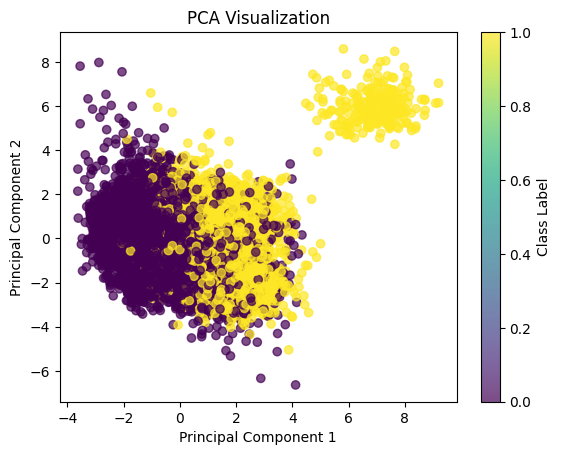

[1.30779803 1.03834739]


In [30]:
plt.scatter(x =data_pca[: , 0] , y =  data_pca[: , 1] , c =  y  , cmap="viridis" ,alpha=0.7   )
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization")
plt.colorbar(label="Class Label")
plt.show()
print(pca.explained_variance_)

In [31]:
print(pca.explained_variance_ratio_)
print(np.cumsum(pca.explained_variance_ratio_))

[0.21796188 0.17305436]
[0.21796188 0.39101623]


In [32]:
tsne =  TSNE(n_components=2)
data_ts = tsne.fit_transform(pca_uncategorized_scaled , y)

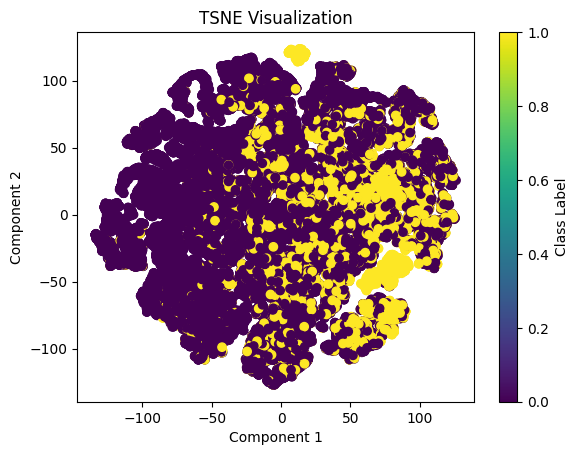

In [33]:
plt.scatter(x =data_ts[: , 0] , y =  data_ts[: , 1] , c =  y  , cmap="viridis"  )
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("TSNE Visualization")
plt.colorbar(label="Class Label")
plt.show()

In [34]:
mca =  prince.MCA(n_components= 2 , random_state= 42)
x_Without_missing_values_mca =  x_Without_missing_values.select_dtypes("category").dropna()
for col in x_Without_missing_values_mca.columns:
    x_Without_missing_values_mca[col] = x_Without_missing_values_mca[col].cat.remove_unused_categories()
data_mca =  mca.fit_transform(x_Without_missing_values_mca)

print(mca.eigenvalues_summary)  

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              0.338         3.00%                      3.00%
1              0.246         2.18%                      5.19%


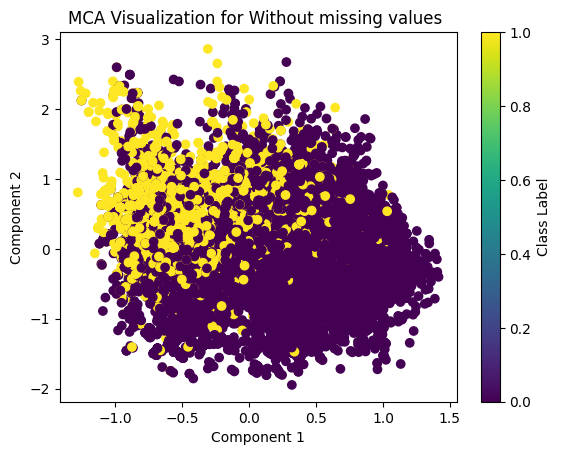

In [35]:
plt.scatter(x =data_mca.iloc[: , 0] , y =  data_mca.iloc[: , 1] , c =  y_Without_missing_values  , cmap="viridis"  )
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("MCA Visualization for Without missing values ")
plt.colorbar(label="Class Label")
plt.show()

In [36]:
mca_data_missing_handled = x_missing_handled.select_dtypes("category").columns 
mca =  prince.MCA(n_components= 2 , random_state= 42)
for i in mca_data_missing_handled:
    x_missing_handled[i] =  x_missing_handled[i].cat.remove_unused_categories()

mca_data = mca.fit_transform(x_missing_handled[mca_data_missing_handled] , y_missing_handled)
print(mca.eigenvalues_summary)  

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              0.341         2.93%                      2.93%
1              0.256         2.20%                      5.13%


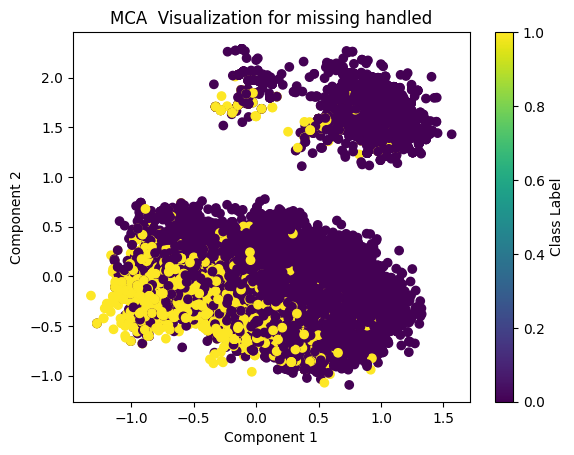

In [37]:
plt.scatter(x =mca_data.iloc[: , 0] , y =  mca_data.iloc[: , 1] , c = y_missing_handled  , cmap="viridis"  )
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("MCA  Visualization for missing handled")
plt.colorbar(label="Class Label")
plt.show()

In [38]:
famd =  prince.FAMD(n_components=2 ,  random_state=42)
num_cols = x_Without_missing_values.select_dtypes(include="number").columns
x_fmad=  x_Without_missing_values.copy()
x_fmad[num_cols] = x_fmad[num_cols].astype(float)
famd_data  =  famd.fit_transform(X= x_fmad )
print(famd.eigenvalues_summary)

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              3.170         3.30%                      3.30%
1              2.576         2.68%                      5.99%


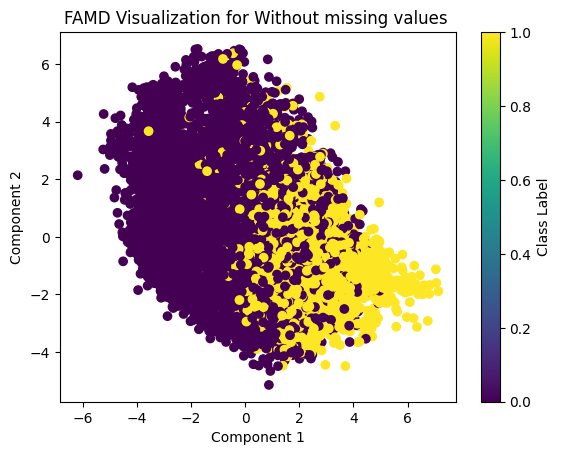

In [39]:
plt.scatter(x =famd_data.iloc[: , 0] , y =  famd_data.iloc[: , 1] , c = y_Without_missing_values  , cmap="viridis"  )
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("FAMD Visualization for Without missing values ")
plt.colorbar(label="Class Label")
plt.show()


In [40]:
num_cols_missing_handled = x_missing_handled.select_dtypes(include="number").columns
x_fmad_missing_handled =  x_missing_handled.copy()
x_fmad_missing_handled[num_cols_missing_handled] =  x_fmad_missing_handled[num_cols_missing_handled].astype(float)
famd_data  =  famd.fit_transform(X= x_fmad_missing_handled )
print(famd.eigenvalues_summary)

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              3.202         3.23%                      3.23%
1              2.530         2.56%                      5.79%


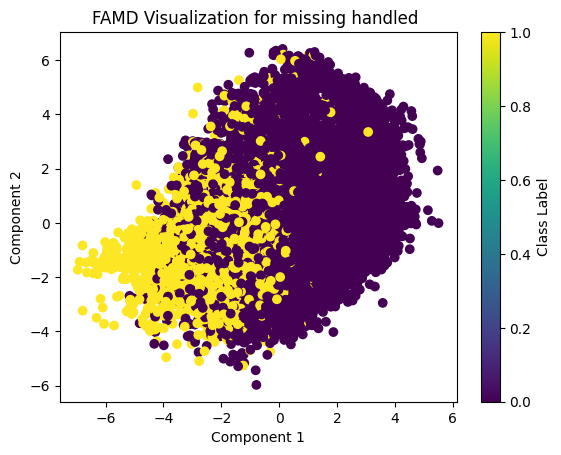

In [41]:
plt.scatter(x =famd_data.iloc[: , 0] , y =  famd_data.iloc[: , 1] , c = y_missing_handled  , cmap="viridis"  )
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("FAMD Visualization for missing handled ")
plt.colorbar(label="Class Label")
plt.show()

In [42]:
def ready_data( x , y ,  batch_size = 1 , emb =  False ) :
    x_temp , x_test , y_temp  , y_test = train_test_split(x , y , random_state=42  , shuffle= True ,
                                                            stratify=y , test_size=0.25)
    
    x_train,  x_valid , y_train , y_valid =  train_test_split(x_temp , y_temp,  random_state=42  , shuffle= True ,
                                                               stratify=y_temp , test_size=0.25)
    
    num_col =  x.select_dtypes(include="number").columns.tolist()
    cat_col =  x.select_dtypes(include= "category").columns.tolist()


    to_y =  lambda s:  torch.tensor(s.values, dtype= torch.float32)
    y_tr, y_va, y_te = to_y(y_train), to_y(y_valid), to_y(y_test)


    if emb :

        process =  ColumnTransformer(transformers=[("num" , StandardScaler() , num_col ),
                                            ("cat" , OrdinalEncoder(handle_unknown="use_encoded_value" , unknown_value=-1) 
                                                , cat_col)]
                                                , remainder='passthrough')
    
        x_train_process =  process.fit_transform(x_train)
        x_test_process =  process.transform(x_test)
        x_valid_process =  process.transform(x_valid)

        n_num = len(num_col)
        cat_sizes =  [ len(c) +1  for c in process.named_transformers_["cat"].categories_]

        def split (a) : 
        
            x_num = torch.tensor(a[: , : n_num] , dtype=torch.float32)
            x_cat  = torch.tensor(a[: , n_num:].astype("int") +1  )
            return x_cat, x_num   
        
        tr_cat , tr_num =  split(x_train_process)
        te_cat ,  te_num =  split(x_test_process)
        va_cat , va_num =  split(x_valid_process)


        train_data = TensorDataset(tr_cat, tr_num, y_tr)
        valid_data = TensorDataset(va_cat, va_num, y_va)
        test_data  = TensorDataset(te_cat, te_num, y_te)
        
        info = {"cat_sizes": cat_sizes, "n_num": n_num}

        
        
    else :

        process =  ColumnTransformer(transformers=[("num" , StandardScaler() , num_col ),
                                            ("cat" , OneHotEncoder(handle_unknown='ignore' , sparse_output = False) 
                                                , cat_col)]
                                                , remainder='passthrough')
        
        x_train_process =  process.fit_transform(x_train)
        x_test_process =  process.transform(x_test)
        x_valid_process =  process.transform(x_valid)

        info = x_train_process.shape[1]

        x_train_ten =  torch.tensor(x_train_process, dtype=torch.float32)
        x_test_ten  =  torch.tensor(x_test_process, dtype=torch.float32)
        x_valid_ten =  torch.tensor(x_valid_process, dtype=torch.float32)

        train_data =  TensorDataset(x_train_ten, y_tr)
        test_data  =  TensorDataset(x_test_ten , y_te)
        valid_data = TensorDataset(x_valid_ten , y_va)



    train_loader =  DataLoader(train_data , batch_size= batch_size , shuffle=True , drop_last=True)
    test_loader =  DataLoader(test_data , batch_size= batch_size , shuffle=False )
    valid_loader =  DataLoader(valid_data , batch_size= batch_size , shuffle=False )
    
    return train_loader ,  test_loader ,  valid_loader , info


    
    

In [43]:
device  = ("cuda"   if torch.cuda.is_available() else  "cpu")

In [44]:
class  model_class(nn.Module) : 
    def __init__(self ,  in_features):
        super().__init__()
        
        self.sq =  nn.Sequential(   nn.Linear(in_features , 128 ) ,
                                    nn.BatchNorm1d(128) , 
                                    nn.ReLU(),
                                    nn.Dropout(0.2),

                                    nn.Linear(128, 64), 
                                    nn.BatchNorm1d(64) , 
                                    nn.ReLU() 
                                    , nn.Dropout(0.2)
                                    ,

                                    nn.Linear(64,32) ,  
                                    nn.BatchNorm1d(32) ,
                                    nn.ReLU() ,  
                                    nn.Dropout(0.2), 
                                    
                                    nn.Linear(32,  1))
    def  forward (self,x) :
        logits = self.sq(x)
        return logits

        

In [45]:
class EmbMLP (nn.Module) :
    def __init__(self, cat_size ,  n_num):
        super().__init__()
        self.embs =nn.ModuleList([nn.Embedding(n , min(50 , (n+1)//2)) for n in cat_size])
        emb_total =  sum(e.embedding_dim for e in self.embs)
        in_features = emb_total + n_num
        self.sq =  nn.Sequential(nn.Linear(in_features , 128 ) ,
                                    nn.BatchNorm1d(128) , 
                                    nn.ReLU(),
                                    nn.Dropout(0.2),

                                    nn.Linear(128, 64), 
                                    nn.BatchNorm1d(64) , 
                                    nn.ReLU() 
                                    , nn.Dropout(0.2)
                                    ,

                                    nn.Linear(64,32) ,  
                                    nn.BatchNorm1d(32) ,
                                    nn.ReLU() ,  
                                    nn.Dropout(0.2), 
                                    
                                    nn.Linear(32,  1))              
    def forward(self, x_cat, x_num):
        vecs = [emb(x_cat[: , i]) for i , emb in enumerate(self.embs)  ]
        x = torch.cat(vecs + [x_num], dim=1)
        logits =  self.sq(x)
        return logits


In [46]:
def train ( data,  model , opt , loss_fn , epochs  , dev , data_valid , emb = False  , th = 0.5 ) :
    min_delta = 0.001
    best_loss = float("inf")
    counter = 0
    flag = 20


    for _ in (pbar := trange(epochs)) : 
        total , total_loss = 0,0
        all_preds  , all_targets = [], []
        model.train()


        if  not emb :
            for x, y in data :
                opt.zero_grad()
                x , y   =  x.to(dev)  , y.to(dev)
                pred    =  model(x).squeeze(1)
                loss    =  loss_fn(pred , y)
                loss.backward()
                opt.step()
                total +=  y.size(0)
                total_loss +=  loss.item()*y.size(0)
                p = (torch.sigmoid(pred)>th)
                all_preds.extend(p.cpu().numpy())
                all_targets.extend(y.cpu().numpy())


        else :
            for x_cat, x_num, y in data:                              
                opt.zero_grad()
                x_cat, x_num, y = x_cat.to(dev), x_num.to(dev), y.to(dev)
                pred = model(x_cat, x_num).squeeze(1)                 
                loss = loss_fn(pred, y)
                loss.backward()
                opt.step()
                total += y.size(0)
                total_loss += loss.item() * y.size(0)
                p = (torch.sigmoid(pred) >th)
                all_preds.extend(p.cpu().numpy())
                all_targets.extend(y.cpu().numpy())

        avg_loss =  total_loss/total
        acc =  accuracy_score(all_targets,all_preds)
        f1 =  f1_score(all_targets,all_preds)
        recall = recall_score(all_targets,all_preds ,  zero_division=0)
        per =  precision_score(all_targets,all_preds ,  zero_division=0)

        model.eval()
        valid_total = 0
        valid_loss = 0

        with torch.no_grad():
            if not  emb :                          
                for x, y in data_valid : 
                    x , y   =  x.to(dev)  , y.to(dev)
                    pred_valid    =  model(x).squeeze(1)
                    loss_valid   =  loss_fn(pred_valid , y)
                    valid_total += y.size(0)
                    valid_loss += loss_valid.item() * y.size(0)
            else : 
                for x_cat, x_num, y in data_valid:                   
                    x_cat, x_num, y = x_cat.to(dev), x_num.to(dev), y.to(dev)
                    pred_valid = model(x_cat, x_num).squeeze(1)      
                    loss_valid = loss_fn(pred_valid, y)
                    valid_total += y.size(0)
                    valid_loss += loss_valid.item() * y.size(0)

            avg_valid_loss = valid_loss / valid_total


            if avg_valid_loss < best_loss - min_delta :
                best_loss = avg_valid_loss
                counter = 0
                best_weights = deepcopy(model.state_dict())
            else :
                counter += 1


            pbar.set_description(
            f"Train Loss: {avg_loss:.4f} | "
            f"Valid Loss: {avg_valid_loss:.4f} | "
            f"Acc: {acc:.4f} | "
            f"F1: {f1:.4f} | "
            f"Recall: {recall:.4f} | "
            f"Precision: {per:.4f}"
        )
            if flag == counter : 
                print("\nEarly Stopping!")
                break
    model.load_state_dict(best_weights)

In [47]:
def test (data, model  , loss_fn ,   dev  , emb =False , th = 0.5) :
    with torch.no_grad() :
        total , total_loss = 0,0
        all_preds  , all_targets = [], []
        model.eval()
        if not emb :
        
            for x , y in data:
                x, y  = x.to(dev) , y.to(dev)
                pred  = model(x).squeeze(1)
                p = (torch.sigmoid(pred)>th)
                loss =  loss_fn(pred , y)
                total     +=  y.size(0)
                total_loss+=  loss.item()*y.size(0)
                all_preds.extend(p.cpu().numpy())
                all_targets.extend(y.cpu().numpy())

        else :
            for x_cat , x_num , y in data :
                x_cat, x_num, y = x_cat.to(dev), x_num.to(dev), y.to(dev)
                pred = model(x_cat, x_num).squeeze(1)
                p = (torch.sigmoid(pred)>th)
                loss =  loss_fn(pred , y)
                total     +=  y.size(0)
                total_loss+=  loss.item()*y.size(0)
                all_preds.extend(p.cpu().numpy())
                all_targets.extend(y.cpu().numpy())

                
        avg_loss =  total_loss/total
        acc =  accuracy_score(all_targets,all_preds)
        f1 =  f1_score(all_targets,all_preds)
        recall = recall_score(all_targets,all_preds)
        per =  precision_score(all_targets,all_preds)
        print(f"loss : {avg_loss} || acc : {acc} || f1 :{f1} || recall  :{ recall} || ps : {per}")
            

In [48]:
batch =  512 
epochs = 40

In [49]:
n_pos = y_Without_missing_values.sum()
n_neg = len(y_Without_missing_values) - n_pos
pos_weight_Without_missing_values = torch.tensor([n_neg / (2*n_pos)], dtype=torch.float32).to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight_Without_missing_values)


In [50]:
train_loader ,  test_loader,  valid_loader ,  info =  ready_data(x_Without_missing_values,  
                                                                 y_Without_missing_values ,  batch)

In [51]:
model_MPl =  model_class(info).to(device)
optimizer  =  torch.optim.Adam(model_MPl.parameters() , lr= 0.001)

Without_missing_values :  train

In [52]:
train(train_loader,  model_MPl,  optimizer , loss_fn , epochs, device ,valid_loader)

Train Loss: 0.3578 | Valid Loss: 0.4026 | Acc: 0.8607 | F1: 0.7305 | Recall: 0.7609 | Precision: 0.7024:  68%|██████▊   | 27/40 [00:19<00:09,  1.38it/s]


Early Stopping!


Without_missing_values :  valid

In [53]:
test( valid_loader ,  model_MPl   , loss_fn ,  device)


loss : 0.3937794106694687 || acc : 0.8482132326925345 || f1 :0.6989473684210527 || recall  :0.7110899571632556 || ps : 0.68721251149954


missing_handled

In [54]:
train_loader_missing_handled,  test_loader_missing_handled ,  valid_loader_missing_handled , info_missing_handled = ready_data(x_missing_handled,  
                                                                                              y_missing_handled , batch)

In [55]:
n_pos = y_missing_handled.sum()
n_neg = len(y_missing_handled) - n_pos
pos_weight_missing_handled = torch.tensor([n_neg / (2*n_pos)], dtype=torch.float32).to(device)
loss_fn_missing_handled = nn.BCEWithLogitsLoss(pos_weight=pos_weight_missing_handled )

In [56]:
model_MPl_missing_handled =  model_class(info_missing_handled).to(device)
optimizer  =  torch.optim.Adam(model_MPl_missing_handled.parameters() , lr= 0.001)


data_train_missing_handled

In [57]:
train(train_loader_missing_handled,  model_MPl_missing_handled,  optimizer , loss_fn_missing_handled
       , epochs, device ,valid_loader_missing_handled)

Train Loss: 0.3580 | Valid Loss: 0.4160 | Acc: 0.8616 | F1: 0.7258 | Recall: 0.7653 | Precision: 0.6901:  57%|█████▊    | 23/40 [00:18<00:13,  1.23it/s]


Early Stopping!


data_valid_missing_handled

In [58]:
test( valid_loader_missing_handled ,  model_MPl_missing_handled   , loss_fn_missing_handled ,  device)

loss : 0.40133854192641755 || acc : 0.8512837612537513 || f1 :0.7041132242370632 || recall  :0.7404651162790697 || ps : 0.6711635750421585


In [59]:
train_loader_emb, test_loader_emb, valid_loader_emb, info_emb = ready_data(x_Without_missing_values, y_Without_missing_values, batch, emb=True)
model_emb = EmbMLP(info_emb["cat_sizes"], info_emb["n_num"]).to(device)
optimizer_emb  =  torch.optim.Adam(model_emb.parameters() , lr= 0.001)
loss_fn_emd =nn.BCEWithLogitsLoss(pos_weight=pos_weight_Without_missing_values)

embeddin

In [60]:
train(train_loader_emb, model_emb , optimizer_emb , loss_fn_emd , epochs , device , valid_loader_emb , True )

Train Loss: 0.3668 | Valid Loss: 0.4054 | Acc: 0.8579 | F1: 0.7196 | Recall: 0.7341 | Precision: 0.7056:  85%|████████▌ | 34/40 [00:32<00:05,  1.04it/s]


Early Stopping!


data_valid_emb

In [61]:
test(valid_loader_emb, model_emb , loss_fn_emd , device , True  )

loss : 0.3951039273919664 || acc : 0.8460903408420805 || f1 :0.7007567071772529 || recall  :0.7272727272727273 || ps : 0.6761061946902654


TEST :

data_test_missing_handled

In [62]:
test( test_loader_missing_handled ,  model_MPl_missing_handled   , loss_fn_missing_handled,  device)

loss : 0.4043995670659389 || acc : 0.8484621155288822 || f1 :0.6973026973026973 || recall  :0.7303801883501918 || ps : 0.6670914303918445


data_test_no_missing

In [63]:
test( test_loader ,  model_MPl   , loss_fn ,  device)

loss : 0.3997235089176717 || acc : 0.8483990801344419 || f1 :0.6967445152158528 || recall  :0.7027123483226267 || ps : 0.6908771929824561


data_test_emb

In [64]:
test(test_loader_emb, model_emb , loss_fn_emd , device , True  )

loss : 0.40303130423349975 || acc : 0.8437997523438882 || f1 :0.6942520775623269 || recall  :0.7155603140613848 || ps : 0.6741761936785474


SMOTENC

In [65]:
cat_cols = x_Without_missing_values.select_dtypes("category").columns.tolist()
num_cols = x_Without_missing_values.select_dtypes(include="number").columns.tolist()

In [66]:
x_temp_sm , x_test_sm ,  y_temp_sm ,  y_test_sm = train_test_split(x_Without_missing_values , y_Without_missing_values ,
                                                                   shuffle= True ,random_state= 42 , 
                                                                   stratify= y_Without_missing_values
                                                        )  
x_train_sm , x_valid_sm ,  y_train_sm ,  y_valid_sm = train_test_split(x_temp_sm , y_temp_sm ,
                                                                   shuffle= True ,random_state= 42 , 
                                                                   stratify= y_temp_sm 
                                                        )  



In [67]:
smote =  SMOTENC(random_state=42 , sampling_strategy="auto" ,  categorical_features=  cat_cols ) 

In [68]:
scaler = StandardScaler()
x_train_sm[num_cols] =  scaler.fit_transform(x_train_sm[num_cols])
x_test_sm[num_cols] =  scaler.transform(x_test_sm[num_cols])
x_valid_sm[num_cols] =  scaler.transform(x_valid_sm[num_cols])

In [69]:
X_train_resampled, y_train_resampled  = smote.fit_resample(
    x_train_sm, y_train_sm
)

In [70]:
process =  ColumnTransformer(transformers=[
                                            ("cat" , OneHotEncoder(handle_unknown='ignore' , sparse_output = False) 
                                                , cat_cols)]
                                                , remainder='passthrough')
        

In [71]:
X_train_resampled_onehot =  process.fit_transform(X_train_resampled)
x_test_sm_onehot  =  process.transform(x_test_sm)
x_valid_sm_onehot =  process.transform(x_valid_sm)

In [72]:
x_train_tensor =  torch.tensor(X_train_resampled_onehot , dtype= torch.float32)
x_test_tensor =  torch.tensor(x_test_sm_onehot , dtype= torch.float32)
x_valid_tensor =  torch.tensor(x_valid_sm_onehot , dtype= torch.float32)


In [73]:
info_sm =  x_train_tensor.size(1)

In [74]:
y_train =  torch.tensor(y_train_resampled.values  ,  dtype=torch.float32)
y_test =  torch.tensor(y_test_sm.values  , dtype= torch.float32)
y_valid =  torch.tensor(y_valid_sm.values  , dtype= torch.float32)

In [75]:
data_train =  TensorDataset(x_train_tensor , y_train)
data_test  =  TensorDataset(x_test_tensor , y_test)
data_valid =  TensorDataset(x_valid_tensor ,  y_valid)

In [76]:
train_loader_sm =  DataLoader(data_train , batch_size= batch , shuffle=True, drop_last=True)
test_loader_sm = DataLoader(data_test , batch_size= batch , shuffle=True )
valid_loader_sm = DataLoader(data_valid , batch_size= batch , shuffle=True )

In [77]:
loss_fn_sm = nn.BCEWithLogitsLoss()
loss_fn_sm_pos_w =  nn.BCEWithLogitsLoss(pos_weight=pos_weight_Without_missing_values)

In [78]:
model_sm =   model_class(info_sm).to(device)
optimizer  =  torch.optim.Adam(model_sm.parameters() , lr= 0.001)

SMOTENC : TRAIN

In [96]:
train(train_loader_sm , model_sm , optimizer,  loss_fn_sm, epochs ,device , valid_loader_sm , th= 0.75)

Train Loss: 0.2801 | Valid Loss: 0.4020 | Acc: 0.8403 | F1: 0.8245 | Recall: 0.7502 | Precision: 0.9151:  55%|█████▌    | 22/40 [00:22<00:18,  1.04s/it]


Early Stopping!


VALID

In [97]:
test(valid_loader_sm, model_sm , loss_fn_sm , device , th=0.75)

loss : 0.3788812632570009 || acc : 0.8482132326925345 || f1 :0.6690665980971973 || recall  :0.6192289386006663 || ps : 0.7276286353467561


TEST 

In [98]:
test(test_loader_sm , model_sm , loss_fn_sm_pos_w , device , th = 0.75 )

loss : 0.4542631425257385 || acc : 0.845657173182381 || f1 :0.6614936954413191 || recall  :0.6084939329050678 || ps : 0.7246068848278793
